# Radiant Descent: Milestone 2

**Team Radiant Descent:** Aunonto Rahman, Michael Dai, Syed Masrur Ahmed

An action-conditioned diffusion world model of Atari Space Invaders: given the last K = 4 frames and
the actions taken at them, the model generates the next frame. Milestone 2 moves to the full dataset,
verifies the pipeline (E1-E5), runs one-change experiments (E6-E8) and analyses errors (E9).

Code cells are folded; click a cell's left edge to show its code. With `RUN_CHECKS = False` (default) the
notebook shows the saved results in `results/milestone2/`; `True` recomputes E1-E3 with
`scripts/m2_checks.py` (needs `data/debug/`).

## 1. Setup

In [1]:
import os
from pathlib import Path

# Run from the repo root wherever the notebook was opened (the root holds ROADMAP.md).
root = Path.cwd().resolve()
while not (root / "ROADMAP.md").exists():
    if root.parent == root:
        raise RuntimeError("Could not find the repo root (no ROADMAP.md above this notebook).")
    root = root.parent
os.chdir(root)

import json
import random
import sys

import numpy as np
import torch
from IPython.display import Image, Markdown, display

SEED = 0
random.seed(SEED), np.random.seed(SEED), torch.manual_seed(SEED)
sys.path.insert(0, str(root / "scripts"))

RESULTS = Path("results/milestone2")
# The checks below are slow on a laptop (E2 ~7 min on CPU, E3 ~15 min on Apple MPS) and need data/debug/.
# False shows the saved results from results/milestone2/; True recomputes them with the same scripts.
RUN_CHECKS = False
HAVE_DEBUG = Path("data/debug").exists()
print(f"torch {torch.__version__}, data/debug: {'found' if HAVE_DEBUG else 'missing'}, RUN_CHECKS={RUN_CHECKS}")

def load(name):
    return json.loads((RESULTS / name).read_text())

def table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

torch 2.14.1, data/debug: found, RUN_CHECKS=False


### Status at a glance

In [2]:
e1, e2 = load("e1/result.json"), load("e2/result.json")
e3 = load("e3/result.json") if (RESULTS / "e3/result.json").exists() else None
se = e2["loss_std_over_draws"] / np.sqrt(e2["draws"])
lk = load("data_debug/stats.json")["leakage"]
table(["", "exercise", "result", "evidence"], [
    ["✅", "Data: full scale", "5,000,000 steps, 6,355 episodes; validator OK; all 5 coverage targets met", "§2"],
    ["✅", "E1 look at the batch", f"{e1['train_windows_match_shard'] + e1['val_windows_match_shard']}/{2 * e1['n']} windows equal the raw rows; "
     "noise and action dropout as specified", "§3 E1"],
    ["✅", "E2 initial loss", f"{e2['loss_mean_over_draws']:.3f} ± {1.96 * se:.3f} measured vs {e2['expected_loss_F0']:.3f} derived "
     "(≈1 only if E[y²] = σ_data²)", "§3 E2"],
    ["⏳", "E3 overfit one batch", "running (500 steps on Apple MPS)", "§3 E3"] if e3 is None else
    ["✅" if e3["log"][-1]["fixed_loss"] < 0.01 else "◐", "E3 overfit one batch",
     f"loss {e3['log'][0]['fixed_loss']:.2f} → {e3['log'][-1]['fixed_loss']:.4f}, sample PSNR "
     f"{e3['log'][0]['psnr']:.1f} → {e3['log'][-1]['psnr']:.1f} dB in {e3['log'][-1]['step']} steps", "§3 E3"],
    ["⏳", "E4 baselines on full data", "Discovery", "§3 E4"],
    ["◐", "E5 leakage + shuffle", f"no shared seeds; {lk['eval']['windows_identical_to_a_train_window'] / lk['eval']['windows']:.1%} "
     "of eval windows duplicate a train window (game start); shuffle run on Discovery", "§2, §3 E5"],
    ["⏳", "E6 data-size curve", "4 runs on Discovery", "§4"],
    ["⏳", "E7 seeds + CI", "3 seeds on Discovery", "§4"],
    ["◐", "E8 experiment plan", "R0 + 4 one-change runs planned", "§4"],
    ["⏳", "E9 error analysis", "after the runs", "§6"],
])

|  | exercise | result | evidence |
|---|---|---|---|
| ✅ | Data: full scale | 5,000,000 steps, 6,355 episodes; validator OK; all 5 coverage targets met | §2 |
| ✅ | E1 look at the batch | 32/32 windows equal the raw rows; noise and action dropout as specified | §3 E1 |
| ✅ | E2 initial loss | 2.417 ± 0.026 measured vs 2.415 derived (≈1 only if E[y²] = σ_data²) | §3 E2 |
| ◐ | E3 overfit one batch | loss 2.41 → 0.0311, sample PSNR 6.7 → 29.8 dB in 500 steps | §3 E3 |
| ⏳ | E4 baselines on full data | Discovery | §3 E4 |
| ◐ | E5 leakage + shuffle | no shared seeds; 7.7% of eval windows duplicate a train window (game start); shuffle run on Discovery | §2, §3 E5 |
| ⏳ | E6 data-size curve | 4 runs on Discovery | §4 |
| ⏳ | E7 seeds + CI | 3 seeds on Discovery | §4 |
| ◐ | E8 experiment plan | R0 + 4 one-change runs planned | §4 |
| ⏳ | E9 error analysis | after the runs | §6 |

## 2. Data

**Full dataset `data/full/`** (collected on Discovery for CP5, `configs/data/full.yaml`): 5,000,000 agent
steps from four play styles, stored as 84×84 RGB frames (max-pooled over the 4-frame skip). A sample is a
**window**: 4 context frames, the 4 actions taken at them, and the next frame as the target. There are no
classes; the closest analogue to "class counts" is the **action distribution** per split, plus the mix of
play styles.

**Splits** (fixed, by episode, never by frame):
- `train` / `val`: `data/full` episodes split by a hash of (shard name, episode id), 5% val (ROADMAP 4.5).
- `eval`: 100 held-out episodes (`data/eval/`, seeds ≥ 1e9, never trained on). CP4 used it to choose the
  inference context level and the sampler steps, so from now on it is treated as **validation**.
- `test`: 100 new held-out episodes (`configs/data/test.yaml`, seeds from 1.5e9), collected for Milestone 2
  and evaluated **once**, on final models only.

In [3]:
summary = load("data_full/collect_summary.json")
rows = [[name, f"{j['steps']:,}", f"{j['episodes']:,}", f"{j['mean_return']:.0f}"] for name, j in summary["jobs"].items()]
rows.append(["**total**", f"**{summary['steps']:,}**", f"**{summary['episodes']:,}**", ""])
table(["play style", "steps", "episodes", "mean score"], rows)
print((RESULTS / "data_full/validate.txt").read_text())

| play style | steps | episodes | mean score |
|---|---|---|---|
| agent_eps0.05 | 1,000,000 | 986 | 726 |
| agent_eps0.2 | 2,000,000 | 2,261 | 517 |
| agent_eps0.3 | 1,000,000 | 1,285 | 404 |
| random | 1,000,000 | 1,823 | 150 |
| **total** | **5,000,000** | **6,355** |  |

$ python scripts/validate_data.py /dartfs-hpc/scratch/f0079km/wm/data/full
rows: 5006355
episodes: 6355
  agent: 4532 episodes, 4004532 rows
  random: 1823 episodes, 1001823 rows
  human: 0 episodes, 0 rows
mean episode length: 787.8 rows
action histogram:
  NOOP           574632   11.5%
  FIRE           741069   14.8%
  RIGHT          681719   13.6%
  LEFT           724960   14.5%
  RIGHTFIRE     1320077   26.4%
  LEFTFIRE       957543   19.2%
disk size: 7162.29 MiB
compression ratio (uncompressed frame bytes / file bytes): 14.11
OK: all invariants hold



Coverage of rare game situations in `data/full` against the targets set in CP2 (all met; wave
transitions went from 24 in the 500k debug set to 488):

In [4]:
report = (RESULTS / "data_full/coverage_report.md").read_text()
display(Markdown(report.split("## Targets")[1].split("## By source")[0]))



| Target | Minimum | Measured | Met |
|---|---|---|---|
| frames with <= 6 invaders left | 5% | 12.15% | yes |
| wave transitions | 50 | 488 | yes |
| game overs | 200 | 6,291 | yes |
| frames with the UFO visible | 1% | 18.35% | yes |
| frames with shields <= 50% intact | 10% | 15.70% | yes |



**Split sizes, action counts per split and leakage** are computed with `scripts/m2_data_stats.py`.
For `data/full` this runs on Discovery (TODO). The same script on the 500k debug set plus `eval`:

In [5]:
stats = load("data_debug/stats.json")
acts = list(next(iter(stats["splits"].values()))["action_share"])
table(["split", "episodes", "windows", "agent / random episodes", "seeds"] + acts,
      [[n, f"{s['episodes']:,}", f"{s['windows']:,}", f"{s['sources'].get('agent', 0)} / {s['sources'].get('random', 0)}",
        f"{s['seed_range'][0]:,}-{s['seed_range'][1]:,}"] + [f"{s['action_share'][a]:.1%}" for a in acts]
       for n, s in stats["splits"].items()])
table(["split vs train", "shared seeds", "frames identical to a train frame", "windows identical to a train window"],
      [[n, l["shared_seeds"], f"{l['frames_identical_to_a_train_frame']:,} / {l['frames']:,}",
        f"{l['windows_identical_to_a_train_window']:,} / {l['windows']:,} "
        f"({l['windows_identical_to_a_train_window'] / l['windows']:.1%})"] for n, l in stats["leakage"].items()])

| split | episodes | windows | agent / random episodes | seeds | NOOP | FIRE | RIGHT | LEFT | RIGHTFIRE | LEFTFIRE |
|---|---|---|---|---|---|---|---|---|---|---|
| train | 654 | 471,846 | 431 / 223 | 0-110,000,056 | 12.0% | 14.6% | 14.0% | 14.2% | 26.2% | 19.0% |
| val | 34 | 26,090 | 26 / 8 | 3-110,000,057 | 11.8% | 15.0% | 13.5% | 14.6% | 26.0% | 19.0% |
| eval | 100 | 39,460 | 70 / 30 | 1,000,000,000-1,030,000,014 | 11.2% | 15.4% | 14.8% | 11.7% | 28.7% | 18.2% |

| split vs train | shared seeds | frames identical to a train frame | windows identical to a train window |
|---|---|---|---|
| val | 0 | 1,682 / 26,226 | 1,038 / 26,090 (4.0%) |
| eval | 0 | 4,685 / 39,860 | 3,041 / 39,460 (7.7%) |

**Leakage findings.**
- No episode seed is shared between train and val/eval, and the split is by episode.
- Still, 4.0% of val windows and 7.7% of eval windows are **byte-identical to a training window** (same 5 frames,
  same 4 actions). 84% of these have their target in the first 32 steps of an episode and 99% in the first 60:
  every game starts from the same screen and the emulator is deterministic, so two episodes that press the same
  buttons early produce the same frames. These are not copied episodes but they are duplicated (and easy)
  examples. Action: single-step metrics are reported on windows whose target is at step ≥ 60 (TODO in the
  E4 refresh), and the rollout evaluation already starts at step 32 (276 of its eval windows are affected).
- Memorization (the diffusion-specific leak): nearest-neighbour check of generated frames against the training
  set is TODO with E9.

## 3. Verification (E1-E5)

### E1: look at the batch
A training batch exactly as the model receives it, built by the real `Trainer` from
`configs/train/debug_aug.yaml` (the settings the final run uses): context noise augmentation (level 0-9,
σ_aug = level/9 × 0.7, the same level for all 4 context frames) and action dropout (all 4 actions replaced by
the `NULL` token with p = 0.1, for classifier-free guidance). Titles: the action taken at each context frame.
Display only: values are clamped to [-1, 1] and upscaled ×3 (no aspect correction).

| check | result |  |
|---|---|---|
| windows equal a direct HDF5 read of their rows (frames and actions), inside one episode | train 16/16, val 16/16 | ✅ |
| measured context noise std vs σ_aug of its level | max relative error 0.8% | ✅ |
| action dropout (all 4 actions NULL) | 2 of 16 samples (p = 0.1) | ✅ |
| val batch: clean context, level 0 | True, True | ✅ |
| value range: targets / noisy context | [-1.00, 0.42] / [-4.1, 3.7] | ✅ |

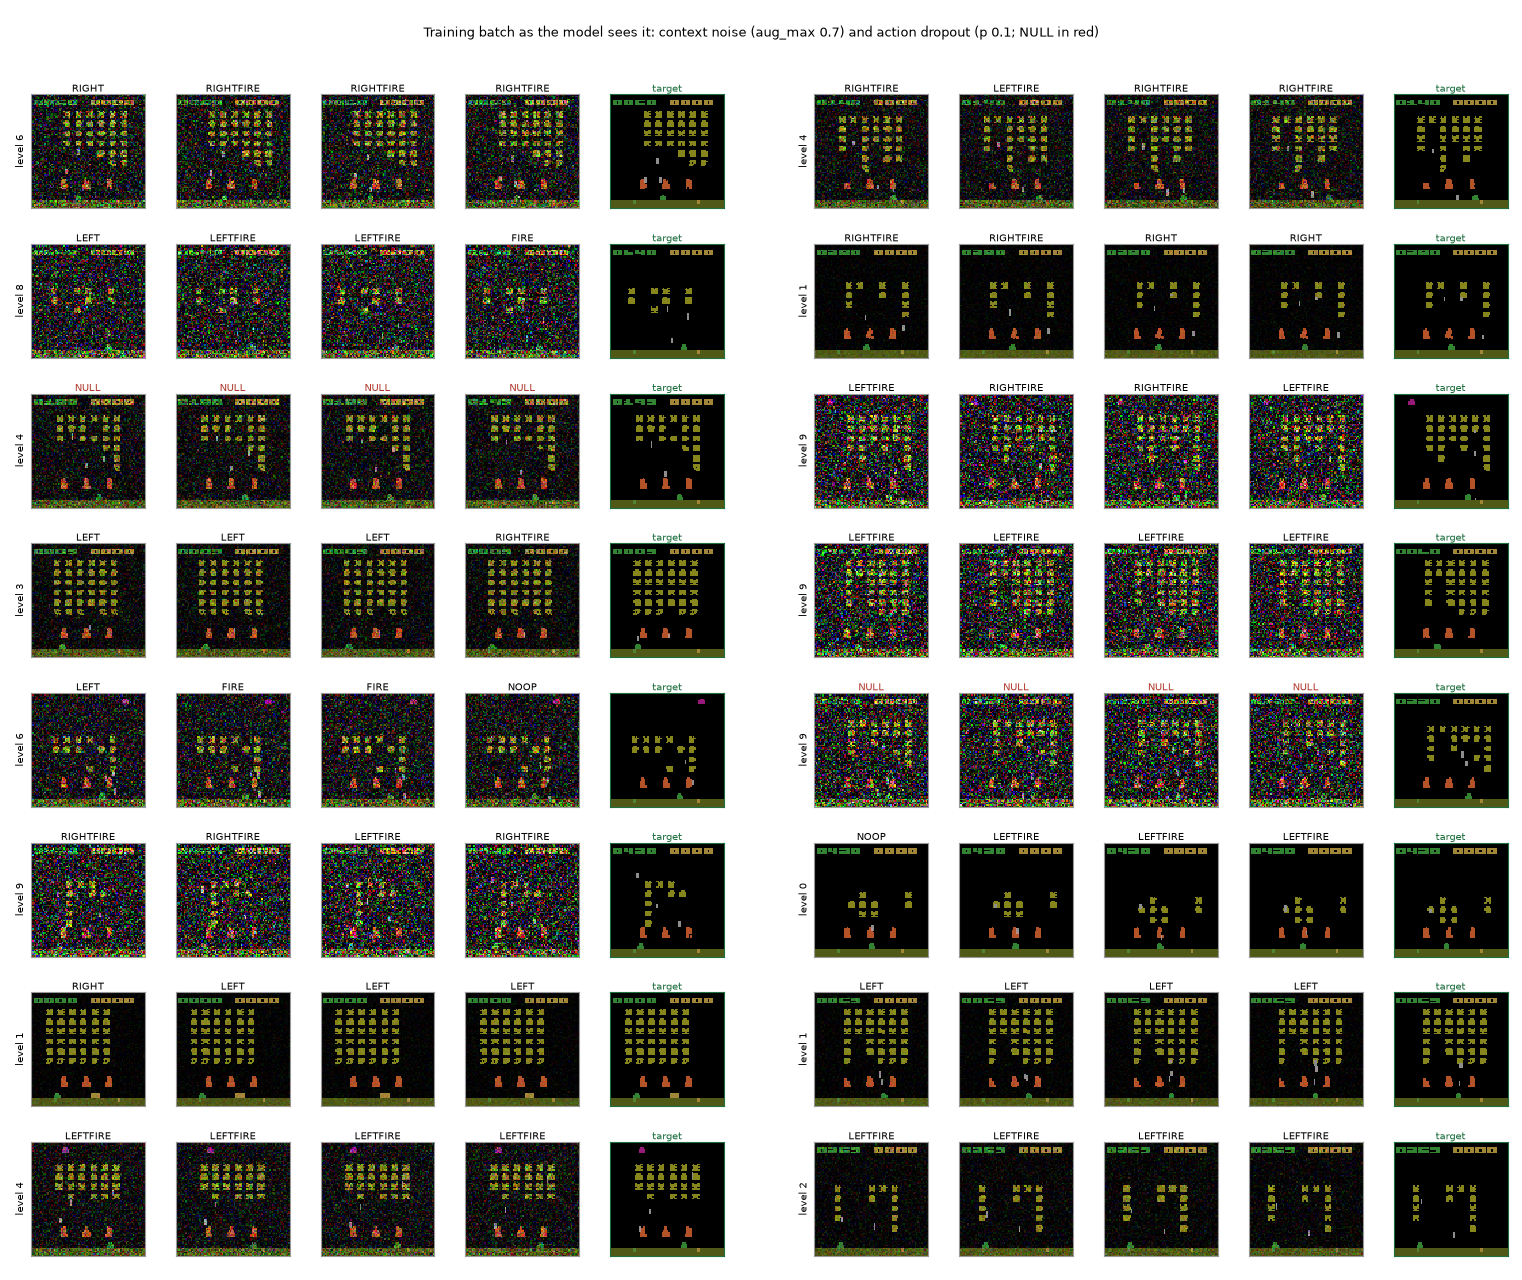

In [6]:
if RUN_CHECKS and HAVE_DEBUG:
    import m2_checks
    from wm.train.trainer import load_run_config
    out = RESULTS / "e1"
    e1 = m2_checks.run_e1(load_run_config("configs/train/debug_aug.yaml", ["data.num_workers=0"]), out)
    (out / "result.json").write_text(json.dumps(e1, indent=2))
e1 = load("e1/result.json")
err = max(abs(s - t) / t for s, t in zip(e1["train_noise_std"], e1["train_sigma_aug"]) if t > 0)
ok = lambda b: "✅" if b else "❌"
table(["check", "result", ""], [
    ["windows equal a direct HDF5 read of their rows (frames and actions), inside one episode",
     f"train {e1['train_windows_match_shard']}/{e1['n']}, val {e1['val_windows_match_shard']}/{e1['n']}",
     ok(e1['train_windows_match_shard'] == e1['val_windows_match_shard'] == e1['n'])],
    ["measured context noise std vs σ_aug of its level", f"max relative error {err:.1%}", ok(err < 0.05)],
    ["action dropout (all 4 actions NULL)", f"{e1['train_dropped_actions']} of {e1['n']} samples (p = 0.1)", "✅"],
    ["val batch: clean context, level 0", f"{e1['val_context_clean']}, {e1['val_ctx_levels_all_zero']}",
     ok(e1['val_context_clean'] and e1['val_ctx_levels_all_zero'])],
    ["value range: targets / noisy context", f"[{e1['target_range'][0]:.2f}, {e1['target_range'][1]:.2f}] / "
     f"[{e1['train_range'][0]:.1f}, {e1['train_range'][1]:.1f}]", "✅"],
])
display(Image(filename=str(RESULTS / "e1/train_batch.png"), width=950))

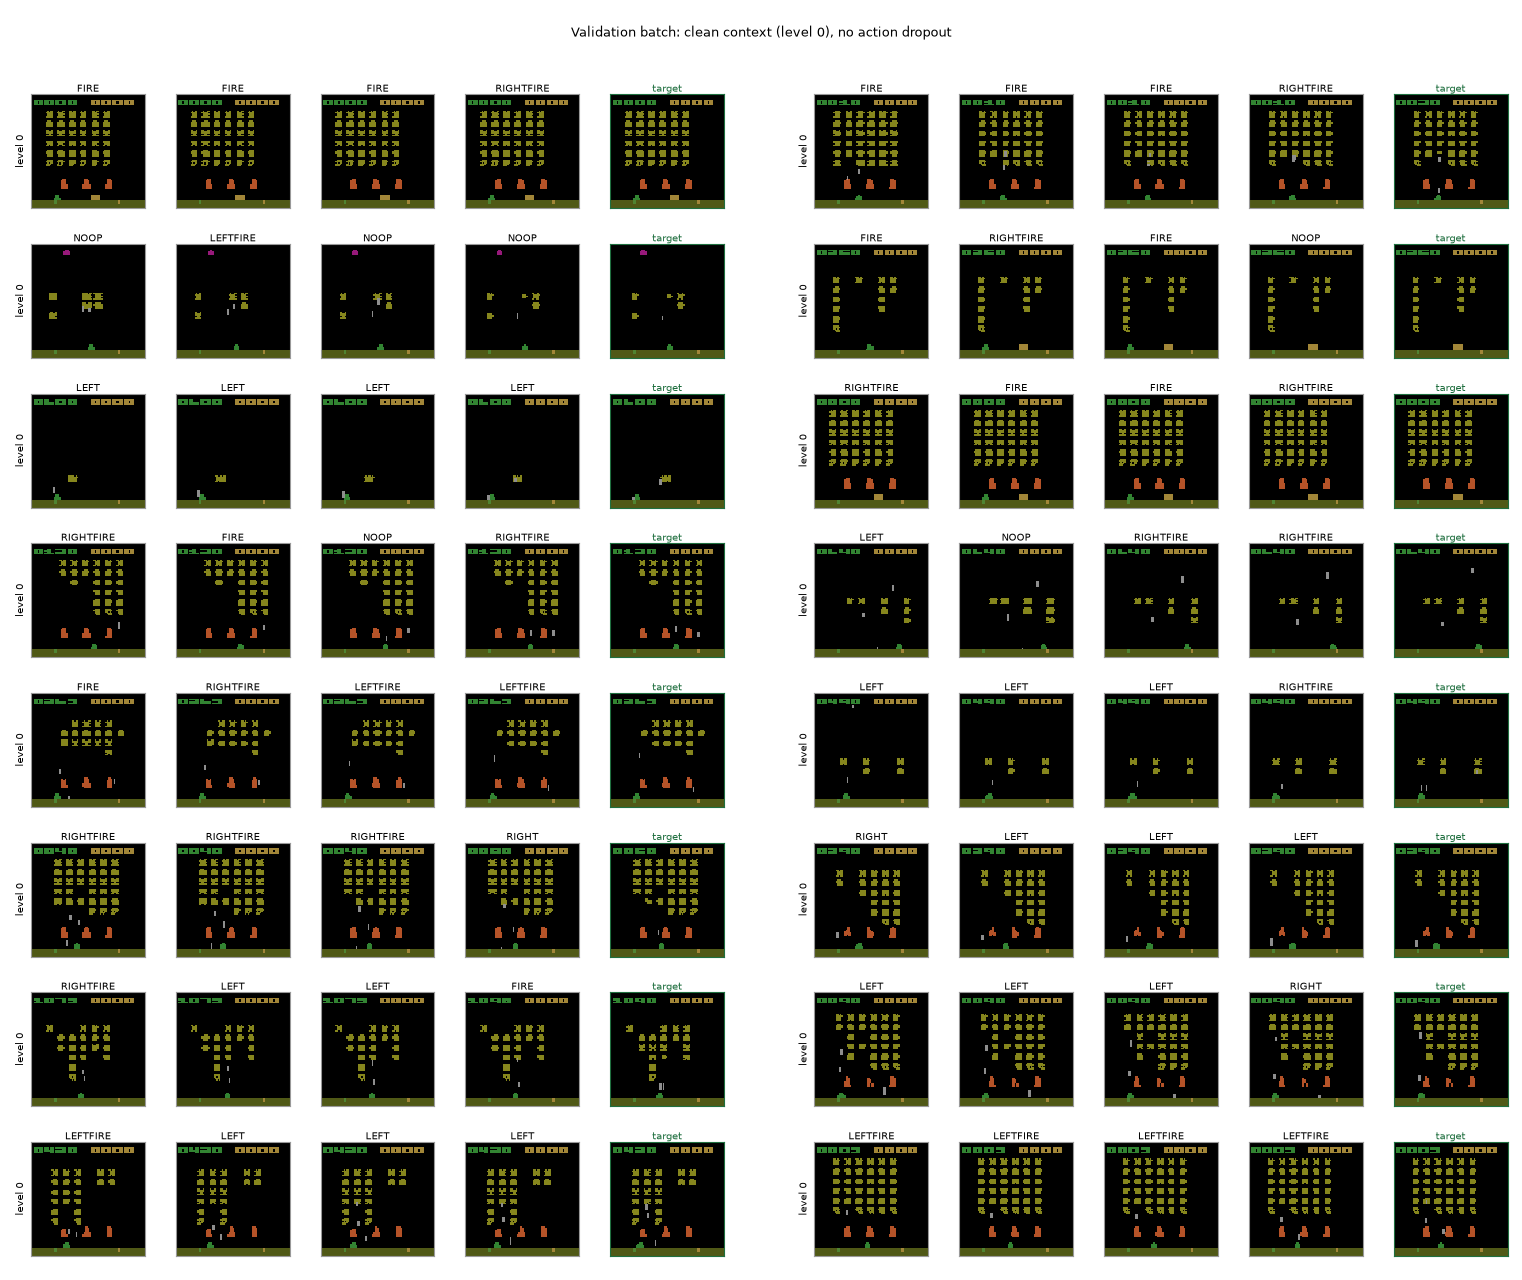

In [7]:
display(Image(filename=str(RESULTS / "e1/val_batch.png"), width=950))

**What we checked and found.**
- *Labels* (here: the actions and the target): every one of the 32 windows equals an independent `h5py` read
  of its rows, the 4 actions are the ones stored at the 4 context frames, and no window crosses an episode
  boundary. Visually, the ship moves the way the actions say (e.g. LEFT×4 keeps it at the left wall).
- *Preprocessing*: frames are in [-1, 1], targets are always clean; noisy contexts leave the range (−4.1 to 3.7),
  by design (the noise is not clamped).
- *Augmentation*: the measured noise std matches σ_aug for every level; at level 9 (σ = 0.7) the scene is
  heavily corrupted but sprites are still visible. Two samples show action dropout (`NULL`).

### E2: initial loss
The slides expect ≈ 1 for diffusion. Our first logged losses were ≈ 2.4, so we derived the right value.
The U-Net's output layer is zero-initialised, so at step 0 the network output is F = 0 and the EDM loss is
E[F_target²] with F_target = (y − c_skip·x)/c_out. For a target y and noise level σ (σ_d = σ_data = 0.5):

$$\mathbb{E}[\text{loss} \mid \sigma] = \frac{\mathbb{E}[y^2]\,\sigma^2 + \sigma_d^4}{\sigma_d^2(\sigma^2+\sigma_d^2)}$$

This equals 1 only when E[y²] = σ_d² = 0.25. Space Invaders frames are mostly black (−1 in our scaling), so
E[y²] ≈ 0.86 and the expected loss, averaged over the training σ distribution, is ≈ 2.4.

| quantity | value |
|---|---|
| largest absolute output F of the fresh network | 0.0 |
| pixel mean, E[y²] of the batch | -0.877, 0.861 (σ_data² = 0.25) |
| expected initial loss (formula) | 2.415 |
| measured, fresh model, 64 σ/noise draws | 2.417 ± 0.026 |
| first logged loss (one draw) | 2.471 |

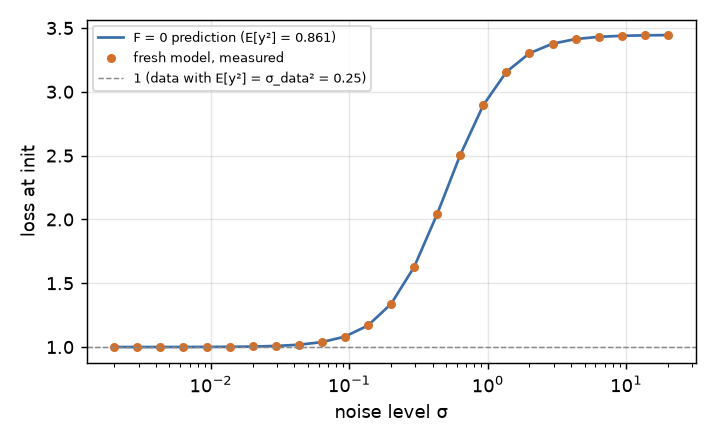

In [8]:
if RUN_CHECKS and HAVE_DEBUG:
    import m2_checks
    from wm.train.trainer import load_run_config
    out = RESULTS / "e2"
    e2 = m2_checks.run_e2(load_run_config("configs/train/debug.yaml", ["data.num_workers=0"]), out)
    (out / "result.json").write_text(json.dumps(e2, indent=2))
e2 = load("e2/result.json")
se = e2["loss_std_over_draws"] / np.sqrt(e2["draws"])
table(["quantity", "value"], [
    ["largest absolute output F of the fresh network", e2["max_abs_F_at_init"]],
    ["pixel mean, E[y²] of the batch", f"{e2['mean_y']:.3f}, {e2['mean_y2']:.3f} (σ_data² = 0.25)"],
    ["expected initial loss (formula)", f"{e2['expected_loss_F0']:.3f}"],
    [f"measured, fresh model, {e2['draws']} σ/noise draws", f"{e2['loss_mean_over_draws']:.3f} ± {1.96 * se:.3f}"],
    ["first logged loss (one draw)", f"{e2['first_batch_loss']:.3f}"],
])
display(Image(filename=str(RESULTS / "e2/initial_loss_vs_sigma.png"), width=600))

**Result: passed.** The measured initial loss matches the derived value within its 95% CI, and the
formula matches the fresh model at every noise level (plot). The value is ≈ 2.4 rather than 1 because our pixel statistics differ from EDM's assumption, not because
of a bug. Consequence for the experiments: with σ_data = 0.5 the EDM loss weighting is not balanced for our data
(large-σ terms weigh up to E[y²]/σ_d² ≈ 3.4× more), so **σ_data = 0.93 (the measured RMS)** is a candidate
one-change experiment for E8.

### E3: overfit one batch
A fresh `small` U-Net (14.3M parameters, R0's architecture), 32 fixed training windows, Adam 10⁻³, no
dropout, weight decay, augmentation or action dropout. The diffusion loss draws a new σ and noise every step,
so it is noisy; we also track the loss on 4 *fixed* σ/noise draws, and the PSNR of 2-step samples against the
32 targets (our analogue of "100% accuracy").

| step | training loss (one draw) | loss, fixed draws | PSNR of samples (dB) |
|---|---|---|---|
| 0 | - | 2.4103 | 6.7 |
| 50 | 0.7011 | 0.7326 | 15.3 |
| 100 | 0.4469 | 0.4717 | 21.9 |
| 150 | 0.5368 | 0.4377 | 22.7 |
| 200 | 0.3212 | 0.3788 | 24.0 |
| 250 | 0.2226 | 0.2474 | 25.5 |
| 300 | 0.0835 | 0.0990 | 26.5 |
| 350 | 0.0474 | 0.0579 | 27.8 |
| 400 | 0.0436 | 0.0478 | 28.7 |
| 450 | 0.0379 | 0.0330 | 29.5 |
| 500 | 0.0245 | 0.0311 | 29.8 |

500 steps on mps in 15.1 min


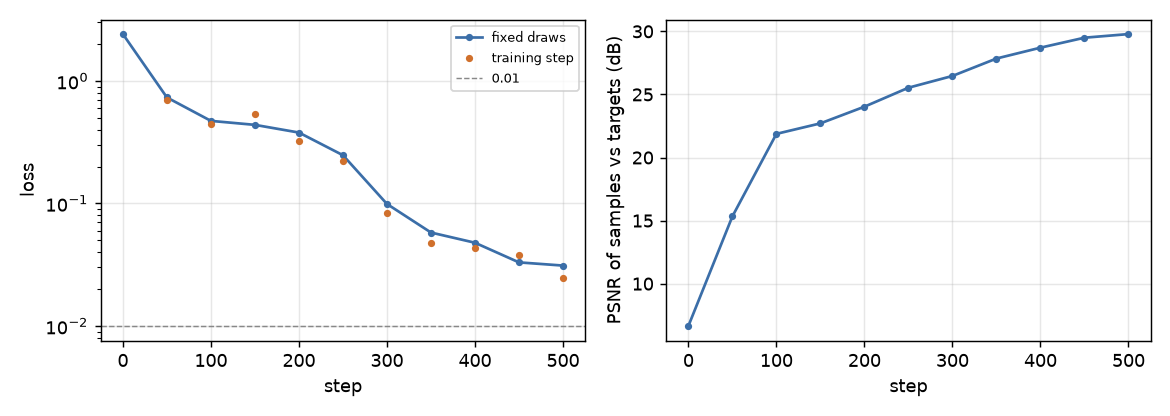

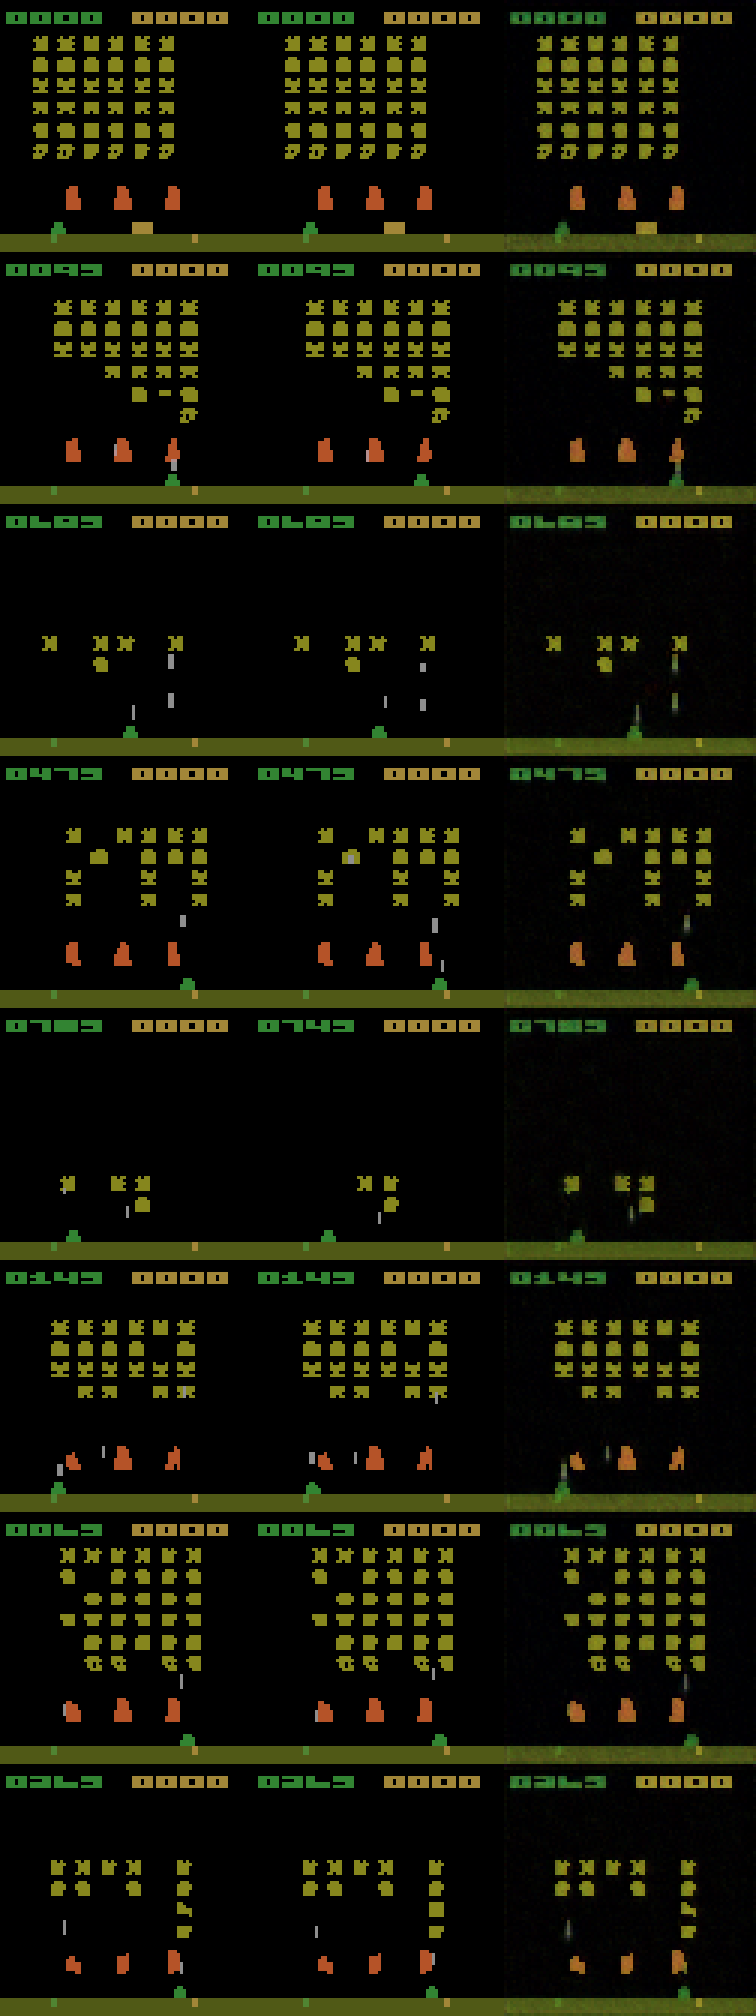

In [9]:
if RUN_CHECKS and HAVE_DEBUG:
    import m2_checks
    from wm.train.trainer import load_run_config
    out = RESULTS / "e3"
    e3 = m2_checks.run_e3(load_run_config("configs/train/debug.yaml", ["data.num_workers=0"]), out, steps=500)
    (out / "result.json").write_text(json.dumps(e3, indent=2))
e3 = load("e3/result.json")
table(["step", "training loss (one draw)", "loss, fixed draws", "PSNR of samples (dB)"],
      [[r["step"], "-" if r["train_loss"] is None else f"{r['train_loss']:.4f}", f"{r['fixed_loss']:.4f}",
        f"{r['psnr']:.1f}"] for r in e3["log"]])
print(f"{e3['steps']} steps on {e3['device']} in {e3['seconds'] / 60:.1f} min")
display(Image(filename=str(RESULTS / "e3/overfit_curve.png"), width=700))
display(Image(filename=str(RESULTS / "e3/overfit_grid.png"), width=420))

**Result: the pipeline can memorize, but 500 steps are not enough for loss < 0.01.**
- The loss on fixed draws fell from 2.41 (the E2 value) to **0.031** (78× lower) and was still falling
  (0.048 → 0.033 → 0.031 over the last 100 steps). The sample PSNR against the 32 targets rose from 6.7 dB
  (noise) to **29.8 dB** and was still rising.
- Grid (last context | target | 2-step sample): the samples reproduce each window's layout, score digits, bullets
  and shields. Two signs it is not fully memorized yet: the samples are slightly dim with faint background
  speckle, and in row 5 the sample keeps an alien that the target has already lost (it leans on the context).
- No sign of a training-loop bug: the loss drops steadily from the expected initial value, nothing is stuck
  or NaN. A diffusion loss is noisier to drive to zero than a classifier's, since every step draws a new
  noise level; at small σ the model must predict the added noise exactly, which needs the target exactly.
- To meet the < 0.01 criterion: continue the same run for more steps (≈ 1,500 more on MPS, ~45 min).


### E4: refresh the baselines on full data (TODO, Discovery)
Copy-last (the floor) vs. the M1 model on `data/full` val windows with target step ≥ 60: PSNR, SSIM, LPIPS,
95% CI, reported as the gap to copy-last.

### E5: leakage and shuffle control (TODO, Discovery)
Leakage: the table in section 2, recomputed on `data/full` + `eval` + `test`. Placebo: train with the
actions shuffled across samples; the model's response to actions (LEFT vs RIGHT, ship position after
30 steps) must fall to chance, while it should be clearly above chance for R0.

## 4. Experiments (E6-E8, TODO)
- **E6** data-size curve: R0 on 10 / 25 / 50 / 100% of `data/full` train episodes, same steps and val windows.
- **E7** seeds: R0 with seeds 0, 1, 2; smallest meaningful difference = max(2×std, CI half-width).
- **E8** one-change runs vs. R0 (= the M1 `small` model on `data/full`, 50k steps):

| ID | change vs. R0 | status |
|---|---|---|
| R0 | M1 model on full data | TODO |
| X1 | context noise augmentation (aug_max 0.7) | TODO (CP4 on debug data: +2.5 dB rollout PSNR at h=20) |
| X2 | sampler steps 2 instead of 3 (inference only) | TODO (CP4 on debug data: better at every h ≥ 5) |
| X3 | σ_data = 0.93 (from E2) | TODO |
| X4 | width: `base` U-Net | TODO |

## 5. Results (TODO)
One test table on `data/test`, evaluated once at the end: copy-last, R0, best one-change model, final model.

## 6. Error analysis (E9, TODO)